# 05 - Bagging: Random Forest

## 1. Objective

Notebook 04 set two baselines for predicting next week's dengue cases (`cases_next`): **persistence** and a single **Decision Tree**. The single tree did **not** beat persistence, because it overfits.

An **ensemble** combines many models, usually decision trees, so that their individual mistakes partly cancel out. There are two main types of tree ensemble. This project treats them in **separate notebooks**:

| Notebook | Ensemble type | Model | How the trees are combined |
|---|---|---|---|
| **05 (this notebook)** | **Bagging** | **Random Forest** | many independent trees trained in parallel, predictions **averaged** |
| 06 | Boosting | XGBoost | trees trained one after another, each one correcting the errors of the trees before it |
| 07 | Comparison | both | bagging vs boosting on the same test rows, with diagnostics |

**Steps in this notebook**
1. **Validation (sections 2-7):** train on target weeks 2007-2022, compare three Random Forest settings on 2023 and choose the best one. The test set is **not used** in these sections.
2. **Final test (section 8):** retrain the chosen setting on all training years (2007-2023) and score it **once** on the test set (2024-2026), next to persistence.
3. **Save (section 9):** the final model and its results, for notebook 07 and the dashboard.

The same 11 features, the same leakage check and the same chronological split as notebook 04 are used.

In [1]:
import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

TRAIN_PATH = Path("../dataset/processed/train.csv")
TEST_PATH = Path("../dataset/processed/test.csv")
MODEL_PATH = Path("../models/05_final_random_forest_model.joblib")
RESULTS_PATH = Path("../models/05_random_forest_results.json")

# the 11 input features created in notebook 03
FEATURES = [
    "current_week_cases",
    "previous_week_cases",
    "previous_2_weeks_cases",
    "previous_3_weeks_cases",
    "seasonal_cases_previous_52_weeks",
    "moving_average_4_weeks",
    "moving_average_8_weeks",
    "weekly_case_change",
    "seasonal_week_sin",
    "seasonal_week_cos",
    "district_code",
]
TARGET = "cases_next"

VALIDATION_YEAR = 2023
RANDOM_STATE = 42
TREE_MAX_DEPTH = 5  # best Decision Tree setting from notebook 04

# chart colours (the same in notebooks 04-07)
COLORS = {"Persistence": "#898781", "Decision Tree": "#eb6834", "Random Forest": "#2a78d6"}
INK, GRID = "#0b0b0b", "#e4e3df"

## 2. Load the data, remove leaky rows, split by time

These are the same steps as notebook 04, repeated so this notebook runs on its own:
1. Load `train.csv` (target weeks up to 2023 only). The test set is loaded later, in section 8.
2. **Leakage check:** remove rows whose current week was interpolated (`is_imputed`). Their value was calculated from next week's cases, i.e. from the target. Also remove rows whose target was interpolated (`target_imputed`).
3. **Chronological split:** train on target weeks 2007-2022, validate on 2023.

In [2]:
data = pd.read_csv(TRAIN_PATH, parse_dates=["start_date", "target_date"])
assert data["target_date"].max() <= pd.Timestamp("2023-12-31")  # no test weeks
assert data[FEATURES + [TARGET]].notna().all().all()
assert TARGET not in FEATURES and "target_log_next" not in FEATURES

# leakage check: interpolated weeks
leaky_or_estimated = data["is_imputed"] | data["target_imputed"]
data = data[~leaky_or_estimated].reset_index(drop=True)
print("removed interpolated rows:", leaky_or_estimated.sum())

# chronological split
target_year = data["target_date"].dt.year
train = data[target_year < VALIDATION_YEAR]
valid = data[target_year == VALIDATION_YEAR]
assert train["target_date"].max() < valid["target_date"].min()

X_train, y_train = train[FEATURES], train[TARGET]
X_valid, y_valid = valid[FEATURES], valid[TARGET]

print("training rows:  ", len(train), "| target weeks", train["target_date"].min().date(), "to", train["target_date"].max().date())
print("validation rows:", len(valid), "| target weeks", valid["target_date"].min().date(), "to", valid["target_date"].max().date())

removed interpolated rows: 52
training rows:   20332 | target weeks 2007-12-29 to 2022-12-31
validation rows: 1352 | target weeks 2023-01-07 to 2023-12-30


## 3. Baselines from notebook 04

- **Persistence:** next week = this week.
- **Decision Tree** with `max_depth = 5` (the best setting in notebook 04). A Random Forest is made of many such trees, so this is the "one tree" reference.

**MAE** is the average error in cases, and **RMSE** gives more weight to large misses. Lower is better for both.

In [3]:
def evaluate(actual, predicted):
    return {"MAE": mean_absolute_error(actual, predicted), "RMSE": root_mean_squared_error(actual, predicted)}

results = []          # validation scores, one row per model
predictions = {}      # validation predictions, used for the charts

predictions["Persistence"] = valid["current_week_cases"].to_numpy()
results.append({"model": "Persistence", "settings": "none", **evaluate(y_valid, predictions["Persistence"])})

decision_tree = DecisionTreeRegressor(max_depth=TREE_MAX_DEPTH, random_state=RANDOM_STATE)
decision_tree.fit(X_train, y_train)
predictions["Decision Tree"] = decision_tree.predict(X_valid)
results.append({"model": "Decision Tree", "settings": f"max_depth={TREE_MAX_DEPTH}",
                **evaluate(y_valid, predictions["Decision Tree"])})

pd.DataFrame(results).round(2)

,model,settings,MAE,RMSE
0,Persistence,none,18.17,41.82
1,Decision Tree,max_depth=5,18.96,43.01


## 4. What is bagging?

**Bagging** = **b**ootstrap **agg**regat**ing**:
1. **Bootstrap:** each tree is trained on a random sample of the training rows, drawn *with replacement*, so every tree sees a slightly different dataset.
2. **Random features:** at each split a tree may only consider a random subset of the features. This makes the trees even more different from each other.
3. **Aggregating:** the forest's prediction is the **average** of all the trees' predictions.

A single deep tree overfits (notebook 04). Averaging many different deep trees cancels much of that noise, which lowers the **variance** of the model. Because the trees do not depend on each other, they can be trained **in parallel**.

A **Random Forest** is bagging of decision trees with the random-feature step added (Breiman, 2001).

**Settings compared** (`n_estimators` = number of trees):

| Setting | Meaning |
|---|---|
| default | 100 trees, grown without limit |
| `min_samples_leaf = 10` | every leaf must contain at least 10 training rows, so the trees are smoother |
| `max_depth = 10` | each tree can ask at most 10 questions in a row |

In [4]:
forest_settings = {
    "default (100 trees)": {"n_estimators": 100},
    "200 trees, min_samples_leaf=10": {"n_estimators": 200, "min_samples_leaf": 10},
    "200 trees, max_depth=10": {"n_estimators": 200, "max_depth": 10},
}

forest_rows = []
forest_models = {}
for name, params in forest_settings.items():
    forest = RandomForestRegressor(**params, random_state=RANDOM_STATE, n_jobs=-1)
    forest.fit(X_train, y_train)
    forest_models[name] = forest

    train_mae = mean_absolute_error(y_train, forest.predict(X_train))
    forest_rows.append({"setting": name, "training MAE": train_mae, **evaluate(y_valid, forest.predict(X_valid))})

forest_results = pd.DataFrame(forest_rows)
forest_results.round(2)

,setting,training MAE,MAE,RMSE
0,default (100 trees),3.80,18.64,43.88
1,"200 trees, min_samples_leaf=10",8.08,18.14,42.32
2,"200 trees, max_depth=10",7.86,18.35,43.42


**What this shows**

- Even the **default forest** (validation MAE 18.64) is far better than a single unlimited tree (28.03 in notebook 04), although each of its trees is also grown without limit. Averaging 100 different trees cancels most of the overfitting. This is the main idea of bagging.
- The training MAE (3.80) is still much lower than the validation MAE, so the default forest still overfits somewhat.
- Requiring **at least 10 rows per leaf** gives the best validation MAE (**18.14**). All three forests beat the best single Decision Tree (18.96).

In [5]:
best_forest_name = forest_results.loc[forest_results["MAE"].idxmin(), "setting"]
best_forest = forest_models[best_forest_name]
RF_PARAMS = forest_settings[best_forest_name]
print("selected Random Forest setting:", best_forest_name, RF_PARAMS)

predictions["Random Forest"] = best_forest.predict(X_valid)
results.append({"model": "Random Forest", "settings": best_forest_name,
                **evaluate(y_valid, predictions["Random Forest"])})

selected Random Forest setting: 200 trees, min_samples_leaf=10 {'n_estimators': 200, 'min_samples_leaf': 10}


**A note on choosing settings.** The setting above was picked using the 2023 validation scores, so these scores are slightly optimistic: we chose the setting that happened to do best on 2023. This is exactly why the test set (2024-2026) is kept separate. It will give the final, unbiased score in section 8.

## 5. Validation results: Random Forest vs the baselines

Validation scores on 2023. The last two columns show the change compared with persistence (negative = better than persistence).

In [6]:
comparison = pd.DataFrame(results).set_index("model")
comparison["MAE vs persistence (%)"] = 100 * (comparison["MAE"] / comparison.loc["Persistence", "MAE"] - 1)
comparison["RMSE vs persistence (%)"] = 100 * (comparison["RMSE"] / comparison.loc["Persistence", "RMSE"] - 1)
comparison.round(2)

,settings,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
model,,,,,
Persistence,none,18.17,41.82,0.00,0.00
Decision Tree,max_depth=5,18.96,43.01,4.37,2.86
Random Forest,"200 trees, min_samples_leaf=10",18.14,42.32,-0.17,1.20


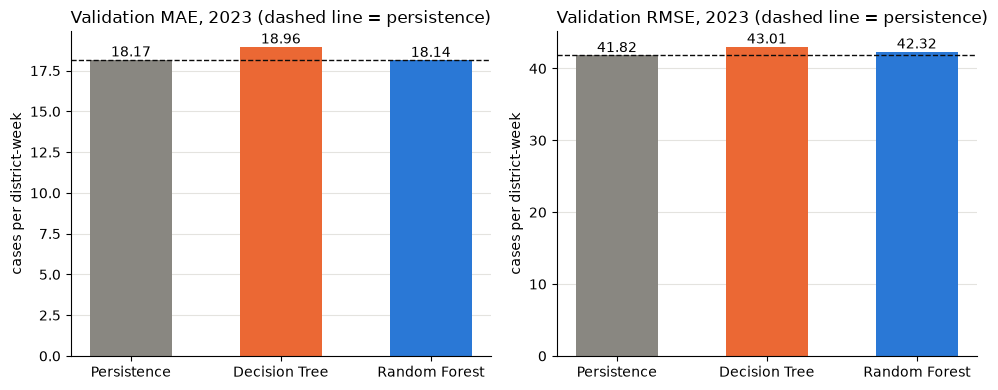

In [7]:
model_names = comparison.index.tolist()
bar_colors = [COLORS[name] for name in model_names]

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric in zip(axes, ["MAE", "RMSE"]):
    values = comparison[metric].to_numpy()
    ax.bar(model_names, values, color=bar_colors, width=0.55)
    for i, v in enumerate(values):
        ax.text(i, v, f"{v:.2f}", ha="center", va="bottom")
    ax.axhline(comparison.loc["Persistence", metric], color=INK, linewidth=1, linestyle="--")
    ax.set_title(f"Validation {metric}, 2023 (dashed line = persistence)", loc="left")
    ax.set_ylabel("cases per district-week")
    ax.grid(axis="y", color=GRID)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**What the validation results show**

- **Bagging clearly beats the single Decision Tree** (MAE 18.14 vs 18.96, RMSE 42.32 vs 43.01). Averaging many trees works better than one tree.
- **Against persistence it is essentially a tie.** The Random Forest has slightly lower MAE (-0.2%) but higher RMSE (+1.2%). A difference of 0.03 cases per district-week, measured on a single year, is too small to call a real improvement.
- **Why the forest cannot do much better:** all features describe *past* case counts, and next week's count is mostly determined by this week's count (see the feature importance in section 7).

## 6. Actual vs predicted: Colombo, 2023

Colombo has the most cases of any district. The chart shows actual weekly cases next to persistence and the Random Forest.

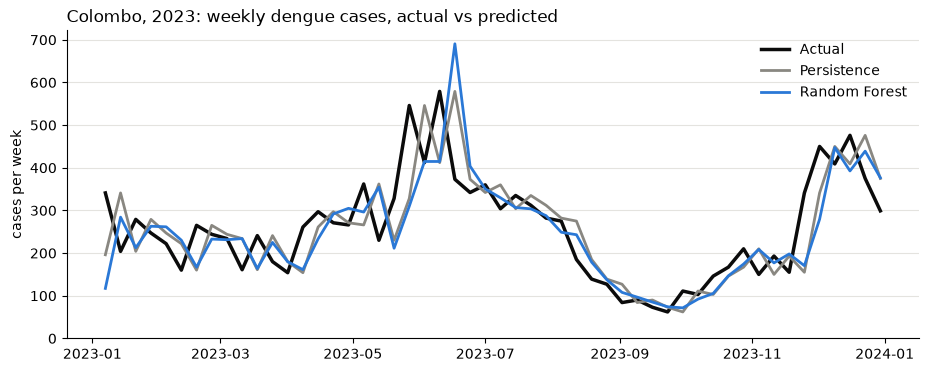

,Persistence,Random Forest
Colombo MAE 2023,65.06,63.02


In [8]:
colombo_rows = (valid["district"] == "Colombo").to_numpy()
colombo_dates = valid.loc[colombo_rows, "target_date"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(colombo_dates, y_valid[colombo_rows], color=INK, linewidth=2.5, label="Actual")
for name in ["Persistence", "Random Forest"]:
    ax.plot(colombo_dates, predictions[name][colombo_rows], color=COLORS[name], linewidth=2, label=name)
ax.set_title("Colombo, 2023: weekly dengue cases, actual vs predicted", loc="left")
ax.set_ylabel("cases per week")
ax.set_ylim(bottom=0)
ax.grid(axis="y", color=GRID)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.show()

pd.DataFrame({name: [mean_absolute_error(y_valid[colombo_rows], predictions[name][colombo_rows])]
              for name in ["Persistence", "Random Forest"]}, index=["Colombo MAE 2023"]).round(2)

Both predictions follow the actual curve about **one week late**: they react to a rise or fall after it has happened. In Colombo, the Random Forest is slightly better than persistence (MAE 63.0 vs 65.1).

## 7. Feature importance

A Random Forest reports how much each feature's splits reduced the squared error, averaged over all trees (**impurity-based importance**). This is a rough guide only: features that are strongly correlated with each other (the lags and moving averages) share the importance between them.

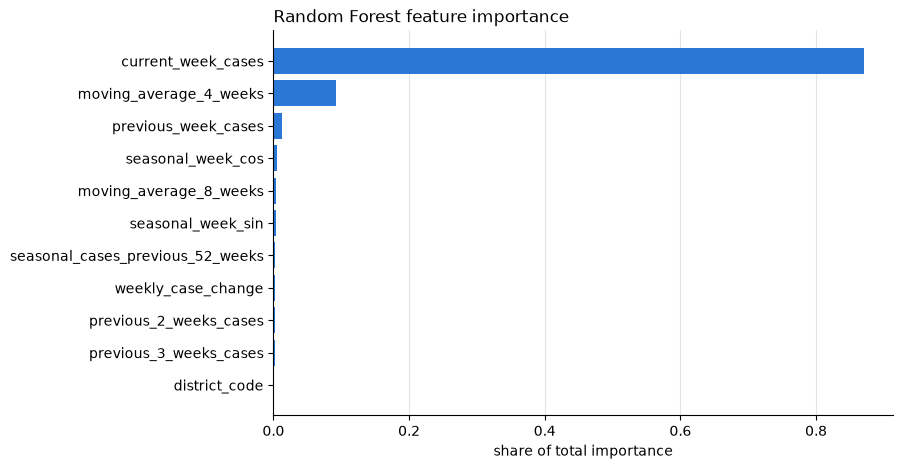

,Random Forest
current_week_cases,0.871
moving_average_4_weeks,0.092
previous_week_cases,0.012
seasonal_week_cos,0.006
moving_average_8_weeks,0.004
seasonal_week_sin,0.004
seasonal_cases_previous_52_weeks,0.003
weekly_case_change,0.003
previous_2_weeks_cases,0.002
previous_3_weeks_cases,0.002


In [9]:
importance = pd.Series(best_forest.feature_importances_, index=FEATURES).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(importance.index, importance.to_numpy(), color=COLORS["Random Forest"])
ax.set_xlabel("share of total importance")
ax.set_title("Random Forest feature importance", loc="left")
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

importance.sort_values(ascending=False).round(3).to_frame("Random Forest")

- The **Random Forest** relies almost entirely on `current_week_cases` (0.87), plus the 4-week moving average (0.09). It has essentially learned the persistence rule, with small adjustments.
- The 52-week seasonal lag, the longer lags and the district code contribute very little.

## 8. Final test (2024-2026)

The setting is now fixed (200 trees, `min_samples_leaf = 10`), so 2023 is no longer needed for choosing anything.

1. **Retrain** the chosen setting on **all** training years (target weeks 2007-2023), so the model also learns from the most recent data.
2. **Load the test set** (`test.csv`, target weeks 2024-2026) for the first time, with the same leakage check.
3. **Score once** against persistence. Nothing is changed after seeing these scores.

**Reproducibility note:** the trees are built in parallel (`n_jobs=-1`) but with a fixed `random_state`, so they are identical every run. When *predicting* in parallel, the 200 tree outputs are added up in a slightly different order each time, which changes results in about the 13th decimal place. Prediction is therefore switched to a single thread (`n_jobs=1`), which makes every prediction exactly repeatable.

In [10]:
test = pd.read_csv(TEST_PATH, parse_dates=["start_date", "target_date"])

# leakage check: interpolated weeks (same rule as for the training data)
test_leaky = test["is_imputed"] | test["target_imputed"]
test = test[~test_leaky].reset_index(drop=True)
print("removed interpolated test rows:", test_leaky.sum())

# safety checks
assert data["target_date"].max() < test["target_date"].min()                       # all training weeks come first
assert test[FEATURES + [TARGET]].notna().all().all()
assert (test["target_date"] - test["start_date"] == pd.Timedelta(days=7)).all()    # target = the following week

X_final, y_final = data[FEATURES], data[TARGET]   # all training years, 2007-2023
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

final_rf = RandomForestRegressor(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)
final_rf.fit(X_final, y_final)
final_rf.set_params(n_jobs=1)  # exactly repeatable predictions

print("final training rows:", len(data), "| target weeks", data["target_date"].min().date(), "to", data["target_date"].max().date(),
      "| training MAE:", round(mean_absolute_error(y_final, final_rf.predict(X_final)), 2))
print("test rows:          ", len(test), "| target weeks", test["target_date"].min().date(), "to", test["target_date"].max().date())

removed interpolated test rows: 106


final training rows: 21684 | target weeks 2007-12-29 to 2023-12-30 | training MAE: 8.5
test rows:           3508 | target weeks 2024-01-06 to 2026-08-29


- **Random Forest:** the average of 200 trees. Each leaf holds real past counts, so it cannot predict below 0 (or above the largest training value).
- **Persistence baseline:** next week = this week (`current_week_cases`).

In [11]:
test_predictions = {
    "Persistence": test["current_week_cases"].to_numpy(dtype=float),
    "Random Forest": final_rf.predict(X_test),
}
assert (test_predictions["Random Forest"] >= 0).all()

test_results = pd.DataFrame({name: evaluate(y_test, p) for name, p in test_predictions.items()}).T
test_results["MAE vs persistence (%)"] = 100 * (test_results["MAE"] / test_results.loc["Persistence", "MAE"] - 1)
test_results["RMSE vs persistence (%)"] = 100 * (test_results["RMSE"] / test_results.loc["Persistence", "RMSE"] - 1)
test_results.round(2)

,MAE,RMSE,MAE vs persistence (%),RMSE vs persistence (%)
Persistence,12.63,29.93,0.0,0.00
Random Forest,12.53,33.63,-0.8,12.37


### Results by test year

2026 only runs until the end of August.

In [12]:
test_year = test["target_date"].dt.year.to_numpy()
year_rows = []
for year in sorted(np.unique(test_year)):
    rows = test_year == year
    row = {"year": int(year), "rows": int(rows.sum()), "mean weekly cases": y_test[rows].mean()}
    for name, p in test_predictions.items():
        row[f"{name} MAE"] = mean_absolute_error(y_test[rows], p[rows])
    row["MAE vs persistence (%)"] = 100 * (row["Random Forest MAE"] / row["Persistence MAE"] - 1)
    year_rows.append(row)

by_year = pd.DataFrame(year_rows).set_index("year")
by_year.round(2)

,rows,mean weekly cases,Persistence MAE,Random Forest MAE,MAE vs persistence (%)
year,,,,,
2024,1352,37.14,10.45,9.53,-8.85
2025,1352,37.57,8.68,8.31,-4.25
2026,804,98.86,22.93,24.66,7.58


**What the test results show**

- **Overall, the Random Forest has a slightly lower MAE than persistence** on the unseen years: 12.53 vs 12.63 (**-0.8%**). Its **RMSE is higher** (33.63 vs 29.93, **+12.4%**), so it makes some very large errors that persistence does not.
- **It depends on the year.** The Random Forest is better than persistence in the moderate years **2024 (-8.8% MAE)** and **2025 (-4.2%)**, and worse in **2026 (+7.6%)**, the year of a very large outbreak (about 99 cases per district-week, compared with about 37 in 2024 and 2025).
- The large errors come from the peaks of the 2026 outbreak. Notebook 07 looks at these weeks in detail and compares them with XGBoost.

## 9. Save the model and the results

- **Model:** `models/05_final_random_forest_model.joblib`, saved with `joblib` (the standard way to save scikit-learn models). A joblib file should be loaded with the same scikit-learn version it was saved with; the version is stored in the results file. It is loaded back and must give exactly the same predictions.
- **Results:** `models/05_random_forest_results.json`: the chosen setting, the validation scores and the test scores. Used by notebooks 07 and 08 and by the dashboard.

**Only load joblib/pickle files from a trusted source** - loading one can run code.

In [13]:
MODEL_PATH.parent.mkdir(exist_ok=True)
joblib.dump(final_rf, MODEL_PATH, compress=3)

loaded_rf = joblib.load(MODEL_PATH)
assert np.array_equal(loaded_rf.predict(X_test), test_predictions["Random Forest"])
print("saved", MODEL_PATH, f"({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")
print("reloaded model gives identical predictions")


def to_dict(table):
    return {str(k): {c: float(v) for c, v in row.items()} for k, row in table.round(3).to_dict(orient="index").items()}


summary = {
    "created_by": "notebooks analysis/05_bagging_random_forest.ipynb",
    "model": "Random Forest",
    "ensemble_type": "bagging",
    "params": RF_PARAMS,
    "random_state": RANDOM_STATE,
    "features": FEATURES,
    "target": TARGET,
    "validation_year": VALIDATION_YEAR,
    "removed_rows": "is_imputed or target_imputed (interpolated weeks)",
    "settings_compared": to_dict(forest_results.set_index("setting")),
    "validation_scores": to_dict(comparison[["MAE", "RMSE"]]),
    "final_train_rows": int(len(data)),
    "test_rows": int(len(test)),
    "test_scores": to_dict(test_results[["MAE", "RMSE"]]),
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__},
}
RESULTS_PATH.write_text(json.dumps(summary, indent=2))
print("saved", RESULTS_PATH)

saved ..\models\05_final_random_forest_model.joblib (9.2 MB)
reloaded model gives identical predictions
saved ..\models\05_random_forest_results.json


## 10. Summary

**Validation (2023)** - trained on 2007-2022

| Model | Type | Settings | Validation MAE | Validation RMSE |
|---|---|---|---|---|
| Persistence | baseline | none | 18.17 | 41.82 |
| Decision Tree | single tree | `max_depth=5` | 18.96 | 43.01 |
| **Random Forest** | **bagging** | 200 trees, `min_samples_leaf=10` | **18.14** | 42.32 |

**Final test (2024-2026)** - trained on 2007-2023, 3,508 district-weeks

| Model | Test MAE | Test RMSE | MAE vs persistence | RMSE vs persistence |
|---|---|---|---|---|
| Persistence | 12.63 | 29.93 | - | - |
| Random Forest | **12.53** | 33.63 | **-0.8%** | +12.4% |

**Key points**
1. **A single tree overfits; bagging fixes much of this.** Averaging 100-200 different trees cut the validation MAE from 28.03 (one unlimited tree) to 18.14-18.64.
2. **Smoother trees generalise better:** at least 10 rows per leaf gave the best validation score.
3. **Persistence is hard to beat** for one-week-ahead forecasts. On the test years the Random Forest is a little better in MAE, better in the moderate years 2024-2025, but worse during the 2026 outbreak and worse in RMSE overall.
4. The leakage check removed interpolated weeks, the setting was chosen on 2023 only, and the test set was used once, so the test scores are fair.

**Saved:** `models/05_final_random_forest_model.joblib`, `models/05_random_forest_results.json`.

**Next:** notebook 06 does the same for **boosting** (XGBoost), and notebook 07 compares the two ensembles on the same test rows.